# ResNet50-Pavimento-Tesis2
**Clasificación del estado del pavimento: Good, Fair y Poor**


## 0. Importaciones



In [ ]:
# %pip install "tensorflow>=2.16,<3" pandas numpy Pillow scikit-learn matplotlib seaborn
# En Colab, si usas Drive:
# from google.colab import drive
# drive.mount('/content/drive')


In [1]:
import os
import json
import math
import hashlib
import platform
from pathlib import Path
from datetime import datetime, timezone
from itertools import combinations

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, cohen_kappa_score, confusion_matrix, classification_report,
)
import tensorflow as tf
from tensorflow.keras import layers, models
from IPython.display import display
from textwrap import fill

print('TensorFlow:', tf.__version__)
print('GPU disponibles:', tf.config.list_physical_devices('GPU'))
tf.keras.backend.clear_session()

TensorFlow: 2.21.0
GPU disponibles: []



## 1. Exploración y Preparación de datos
### 1.1. Configuración central
`CROP_BOTTOM_PX=10` conserva la altura usada en el original, **como valor inicial por revisar**.
No se conoce la altura exacta de la marca en las nuevas imágenes: compruébala en la sección 5.
El recorte elimina únicamente filas inferiores, conserva todo el ancho y no modifica los archivos originales.

La separación usa por defecto `(nombre_avenida, calzada, tramo_id)` como unidad de muestreo.
Verifica que esta combinación identifique realmente una misma unidad física. Si cuentas con
un identificador global de UM, puedes usar `GROUP_COLUMNS = ['um_id']`.
No agrupes por una columna que identifique cada imagen individualmente.


In [2]:
CSV_PATH = Path('data_final_v4.csv')
IMG_DIR = Path('carpeta_imagenes')
OUTPUT_ROOT = Path('resultados_resnet50_tesis2')
RANDOM_STATE = 42
CLASS_NAMES = ['Good', 'Fair', 'Poor']
CLASS_ORDER = CLASS_NAMES
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
EXPECTED_COUNTS = {'Good': 581, 'Fair': 1196, 'Poor': 1042}
STRICT_EXPECTED_COUNTS = True

TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.70, 0.15, 0.15
SPLIT_MODE = 'group'  # 'group' recomendado; 'stratified' reproduce el método anterior
GROUP_COLUMNS = ['nombre_avenida', 'calzada', 'tramo_id']
SPLIT_CANDIDATES = 300

IMG_SIZE = (320,320)  # alto, ancho; 320×320 es un experimento opcional más costoso
CROP_BOTTOM_PX = 25
BATCH_SIZE = 32  # reducir a 16 u 8 si falta memoria
BALANCE_MODE = 'sqrt'  # 'sqrt', 'none' o 'balanced'; nunca aplica oversampling
EPOCHS_PHASE1, EPOCHS_PHASE2 = 15, 30
LR_PHASE1, LR_PHASE2 = 1e-3, 1e-5
SEED = RANDOM_STATE
AUTOTUNE = tf.data.AUTOTUNE

assert np.isclose(TRAIN_SIZE + VAL_SIZE + TEST_SIZE, 1.0)
assert min(TRAIN_SIZE, VAL_SIZE, TEST_SIZE) > 0
assert isinstance(CROP_BOTTOM_PX, int) and CROP_BOTTOM_PX >= 0
assert SPLIT_MODE in {'group', 'stratified'}
assert BALANCE_MODE in {'sqrt', 'none', 'balanced'}

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print('La GPU ya estaba inicializada:', exc)

#Una carpeta nueva por ejecución evita mezclar checkpoints antiguos.
#RUN_ID = (
#    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
#    + f"_{IMG_SIZE[0]}"
#)

RUN_ID = "20261011T103854105172Z_320"
RUN_DIR = OUTPUT_ROOT / RUN_ID
SPLITS_DIR = RUN_DIR / 'splits'
MODEL_DIR = RUN_DIR / 'modelos'

for folder in (SPLITS_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print('Resultados de esta ejecución:', RUN_DIR.resolve())


Resultados de esta ejecución: C:\Users\Diego\Desktop\Tesis_Pavimento\resultados_resnet50_tesis2\20261011T103854105172Z_320


,cantidad,porcentaje
pci_clase,,
Good,581,20.61
Fair,1196,42.43
Poor,1042,36.96


Total: 2819; razón mayoritaria/minoritaria: 2.06:1


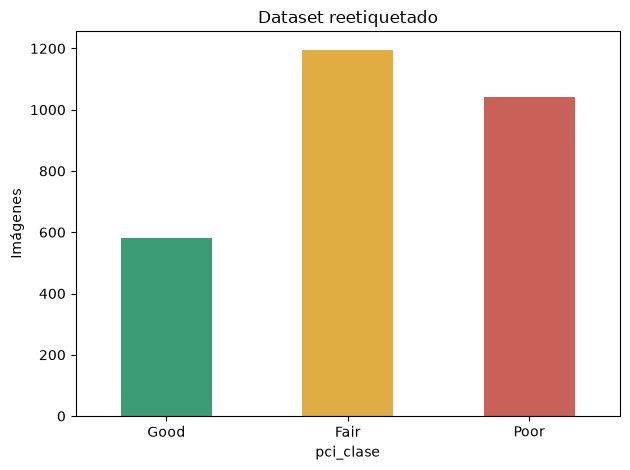

In [3]:
# 1.2. CARGA Y VALIDACIÓN DEL CSV REETIQUETADO
if not CSV_PATH.is_file() or not IMG_DIR.is_dir():
    raise FileNotFoundError('Configura CSV_PATH e IMG_DIR con el CSV nuevo y su carpeta de imágenes.')

df = pd.read_csv(CSV_PATH, dtype=str)
df.columns = df.columns.str.strip()
required_cols = {'nombre_imagen', 'pci_clase', *GROUP_COLUMNS}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f'Faltan columnas: {sorted(missing)}')
for col in required_cols:
    if df[col].isna().any():
        raise ValueError(f'Hay valores nulos en {df[df.isnull().any(axis=1)]}. Corrígelos antes de entrenar.')
    df[col] = df[col].str.strip()
    if df[col].eq('').any():
        raise ValueError(f'Hay valores vacíos en {col}.')

if df['nombre_imagen'].duplicated().any():
    display(df[df['nombre_imagen'].duplicated(keep=False)])
    raise ValueError('Hay nombres de imagen repetidos; revisa el CSV.')

unknown = set(df['pci_clase']) - set(CLASS_NAMES)
if unknown:
    raise ValueError(f'Etiquetas no válidas: {unknown}. Usa solo Good, Fair y Poor ya reetiquetadas.')
counts = df['pci_clase'].value_counts().reindex(CLASS_NAMES, fill_value=0)
if (counts == 0).any():
    raise ValueError('Falta al menos una de las tres clases.')
if STRICT_EXPECTED_COUNTS and counts.to_dict() != EXPECTED_COUNTS:
    raise ValueError(f'Conteos encontrados: {counts.to_dict()}; esperados: {EXPECTED_COUNTS}. '
                     'Revisa el CSV. Cambia STRICT_EXPECTED_COUNTS solo si el dataset cambió intencionalmente.')

# Orden estable para que el split no cambie si solo se reordena el CSV.
df = df.sort_values('nombre_imagen').reset_index(drop=True)
df['label'] = df['pci_clase'].map(CLASS_TO_IDX).astype('int32')
df['group_id'] = df[GROUP_COLUMNS].apply(
    lambda row: json.dumps(row.tolist(), ensure_ascii=False), axis=1
)
df['path'] = df['nombre_imagen'].map(lambda name: str((IMG_DIR / name).resolve()))
if df['path'].duplicated().any():
    raise ValueError('Dos nombres apuntan al mismo archivo físico.')

distribution = pd.DataFrame({'cantidad': counts, 'porcentaje': 100 * counts / len(df)})
display(distribution.round(2))
print(f'Total: {len(df)}; razón mayoritaria/minoritaria: {counts.max()/counts.min():.2f}:1')
ax = counts.plot.bar(color=['#3b9d75', '#e1ac42', '#c96158'], rot=0, title='Dataset reetiquetado')
ax.set_ylabel('Imágenes')
plt.tight_layout()
plt.show()


In [4]:
# 1.3. INTEGRIDAD Y DUPLICADOS DE CONTENIDO
issues, image_info = [], []
for row in df.itertuples(index=False):
    try:
        with Image.open(row.path) as im:
            im.verify()
        with Image.open(row.path) as im:
            if im.getexif().get(274, 1) != 1:
                raise ValueError('Orientación EXIF distinta de 1: normaliza la orientación antes de entrenar.')
            rgb = im.convert('RGB')
            width, height = rgb.size
            if height <= CROP_BOTTOM_PX:
                raise ValueError('El recorte inferior deja la imagen vacía.')
            if im.format not in {'JPEG', 'PNG'}:
                raise ValueError(f'Formato {im.format}: convierte a JPEG o PNG para este pipeline.')
            # Hash de píxeles: también encuentra copias iguales con metadatos distintos.
            digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
            image_info.append((width, height, im.format, digest))
    except Exception as exc:
        issues.append({'nombre_imagen': row.nombre_imagen, 'error': str(exc)})

if issues:
    pd.DataFrame(issues).to_csv(RUN_DIR / 'imagenes_invalidas.csv', index=False)
    display(pd.DataFrame(issues).head(20))
    raise ValueError('Corrige los archivos indicados; no se eliminan imágenes silenciosamente.')

df[['width', 'height', 'format', 'pixel_sha256']] = pd.DataFrame(image_info, index=df.index)
duplicates = df[df['pixel_sha256'].duplicated(keep=False)]
if not duplicates.empty:
    duplicates.to_csv(RUN_DIR / 'duplicados_contenido.csv', index=False)
    display(duplicates[['nombre_imagen', 'pci_clase', 'group_id']])
    raise ValueError('Hay imágenes con píxeles idénticos. Revisa copias/etiquetas y vuelve a ejecutar.')

print('Imágenes verificadas:', len(df))
display(df.groupby(['width', 'height', 'format']).size().rename('cantidad').reset_index())
print('El hash no detecta panoramas similares, versiones recomprimidas ni cercanía espacial.')


Imágenes verificadas: 2819


,width,height,format,cantidad
0,640,640,JPEG,2819


El hash no detecta panoramas similares, versiones recomprimidas ni cercanía espacial.


## 2. División de datos
La tesis describe varias capturas por unidad de muestreo. Un split aleatorio por imagen puede
colocar vistas relacionadas en entrenamiento y prueba. Por eso el valor predeterminado es
**separar unidades completas** y aproximar 70/15/15 y la distribución de clases.

Se prueban particiones de metadatos y se elige la que mejor conserva tamaño y proporciones;
**no se usan predicciones, métricas del modelo ni píxeles para escoger la partición**.
Los porcentajes serán aproximados porque una unidad no se fragmenta. Si no es posible incluir
las tres clases en cada conjunto, se detiene con un mensaje, sin cambiar de método automáticamente.
La opción `stratified` mantiene el procedimiento del original como comparación metodológica.

Mantener una UM fuera de train no garantiza independencia entre tramos vecinos o panoramas
compartidos entre distintas UM. Si esos casos existen, define grupos más amplios previamente.
Una prueba por avenida completa responde a generalización a avenidas nuevas y es otro protocolo.


## Cargar si ya hay partición

In [6]:
def cargar_particion(nombre):
    frame = pd.read_csv(
        SPLITS_DIR / f"{nombre}.csv",
        dtype={"nombre_imagen": str, "tramo_id": str},
    )

    # Reconstruir rutas según la ubicación actual de las imágenes.
    frame["path"] = frame["nombre_imagen"].map(
        lambda nombre: str((IMG_DIR / nombre).resolve())
    )

    frame["label"] = (
        frame["pci_clase"].map(CLASS_TO_IDX).astype("int32")
    )

    faltantes = [
        ruta for ruta in frame["path"]
        if not Path(ruta).is_file()
    ]
    if faltantes:
        raise FileNotFoundError(
            f"Faltan {len(faltantes)} imágenes en {nombre}. "
            f"Revisa IMG_DIR. Ejemplo: {faltantes[0]}"
        )

    return frame

train_df = cargar_particion("train")
val_df = cargar_particion("val")
test_df = cargar_particion("test")
splits = {
    'train': train_df,
    'val': val_df,
    'test': test_df
}

FileNotFoundError: [Errno 2] No such file or directory: 'resultados_resnet50_tesis2\\20261011T103854105172Z_320\\splits\\train.csv'

## Crear nueva partición

In [ ]:
def best_group_holdout(frame, holdout_fraction, seed, n_candidates=300):
    """Busca aproximación de tamaños y clases manteniendo cada group_id íntegro."""
    if frame['group_id'].nunique() < 3:
        raise ValueError('Muy pocos grupos para dividir. Revisa GROUP_COLUMNS.')
    target_dist = frame['pci_clase'].value_counts(normalize=True).reindex(CLASS_NAMES, fill_value=0)
    splitter = GroupShuffleSplit(n_splits=n_candidates, test_size=holdout_fraction, random_state=seed)
    best, best_score = None, np.inf
    for left_idx, right_idx in splitter.split(frame, frame['label'], groups=frame['group_id']):
        left, right = frame.iloc[left_idx], frame.iloc[right_idx]
        if any(part['label'].nunique() != NUM_CLASSES for part in (left, right)):
            continue
        size_error = abs(len(right) / len(frame) - holdout_fraction)
        dist_error = sum(
            (part['pci_clase'].value_counts(normalize=True).reindex(CLASS_NAMES, fill_value=0)
             - target_dist).abs().mean()
            for part in (left, right)
        )
        score = size_error + dist_error
        if score < best_score:
            best_score, best = score, (left.copy(), right.copy())
    if best is None:
        raise ValueError('No se encontró un split por grupos con las tres clases. '
                         'Revisa cantidad y distribución de UM por clase o aumenta SPLIT_CANDIDATES.')
    return tuple(part.reset_index(drop=True) for part in best)

if SPLIT_MODE == 'group':
    train_df, temp_df = best_group_holdout(df, VAL_SIZE + TEST_SIZE, SEED, SPLIT_CANDIDATES)
    val_df, test_df = best_group_holdout(
        temp_df, TEST_SIZE / (VAL_SIZE + TEST_SIZE), SEED + 1, SPLIT_CANDIDATES
    )
else:
    train_df, temp_df = train_test_split(
        df, train_size=TRAIN_SIZE, stratify=df['label'], random_state=SEED
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=TEST_SIZE/(VAL_SIZE + TEST_SIZE),
        stratify=temp_df['label'], random_state=SEED
    )
    train_df, val_df, test_df = [part.reset_index(drop=True) for part in (train_df, val_df, test_df)]

splits = {'train': train_df, 'val': val_df, 'test': test_df}
assert sum(map(len, splits.values())) == len(df)
for (name_a, a), (name_b, b) in combinations(splits.items(), 2):
    assert set(a['nombre_imagen']).isdisjoint(b['nombre_imagen'])
    assert set(a['pixel_sha256']).isdisjoint(b['pixel_sha256'])
    overlap = set(a['group_id']) & set(b['group_id'])
    if SPLIT_MODE == 'group':
        assert not overlap, f'Grupos compartidos entre {name_a} y {name_b}'
    else:
        print(f'UM compartidas {name_a}/{name_b}: {len(overlap)}')

split_summary = pd.DataFrame({
    name: part['pci_clase'].value_counts().reindex(CLASS_NAMES, fill_value=0)
    for name, part in splits.items()
})
display(split_summary)
display(pd.DataFrame({name: {'imagenes': len(part), 'porcentaje': 100*len(part)/len(df),
                             'grupos': part['group_id'].nunique()} for name, part in splits.items()}).T.round(2))
for name, part in splits.items():
    if part['label'].nunique() != NUM_CLASSES:
        raise ValueError(f'Faltan clases en {name}.')
    part.to_csv(SPLITS_DIR / f'{name}.csv', index=False)
split_summary.to_csv(SPLITS_DIR / 'distribucion.csv')
print('Conserva estos mismos splits para comparar ResNet50, VGG16, ConvNeXt y Swin.')


## 3. Preprocesamiento
### 3.1. Solo recorte inferior, redimensionado y normalización de ResNet50
No hay recorte central, RandomZoom, RandomCrop ni rotaciones. Se mantiene todo el campo visible
salvo la franja inferior. El redimensionado a 224×224 no recorta, aunque reduce resolución y
produce una ligera deformación al convertir 640×630 en un cuadrado.
Esto conserva el encuadre, **no todos los detalles de la resolución original**.
Puedes comparar 320×320 usando únicamente validación, con mayor costo de cómputo.

`preprocess_input` recibe RGB float32 en escala 0–255, convierte a BGR y resta las medias
correspondientes. No se divide adicionalmente entre 255.


In [ ]:
def decode_rgb(path):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    return tf.cast(image, tf.float32)

def crop_bottom_only(image, crop_bottom_px=CROP_BOTTOM_PX):
    height = tf.shape(image)[0]
    tf.debugging.assert_greater(height, crop_bottom_px, message='Recorte inferior inválido')
    return image[:height - crop_bottom_px, :, :]

def load_and_resize_image(path, label):
    image = crop_bottom_only(decode_rgb(path))
    image = tf.image.resize(image, IMG_SIZE, method='bilinear', antialias=True)
    image = tf.ensure_shape(image, (*IMG_SIZE, 3))
    return image, label

def apply_resnet_preprocess(image, label):
    return tf.keras.applications.resnet50.preprocess_input(image), label

# Variaciones suaves de iluminación y reflejo horizontal solo en entrenamiento.
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal', seed=SEED),
    layers.RandomBrightness(0.08, value_range=(0, 255), seed=SEED + 1),
    layers.RandomContrast(0.08, seed=SEED + 2),
], name='data_augmentation')

def augment_batch(images, labels):
    images = data_augmentation(images, training=True)
    return tf.clip_by_value(images, 0.0, 255.0), labels

def build_dataset(frame, training=False):
    paths = frame['path'].to_numpy(dtype=str)
    labels = frame['label'].to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_and_resize_image, num_parallel_calls=AUTOTUNE, deterministic=True)
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    if training:
        # No paralelizamos el generador aleatorio para mantener un orden reproducible.
        ds = ds.map(augment_batch)
    ds = ds.map(apply_resnet_preprocess, num_parallel_calls=AUTOTUNE, deterministic=True)
    return ds.prefetch(AUTOTUNE)

train_ds = build_dataset(train_df, training=True)
val_ds = build_dataset(val_df)
test_ds = build_dataset(test_df)


### 3.2. Desbalance: sin oversampling y con pesos moderados
Good representa aproximadamente 13.37% del dataset y Fair tiene 3.51 veces más imágenes.
Sigue existiendo desbalance, pero no se repiten imágenes artificialmente.

El punto de partida es `BALANCE_MODE='sqrt'`: se calcula el peso inverso balanceado
`N_train / (3 × n_clase_train)`, se toma su raíz cuadrada y se normaliza para que el peso
promedio por imagen de train sea 1. Esto da una compensación intermedia entre no ponderar
y equilibrar totalmente las clases. **Es una elección experimental, no un óptimo demostrado.**

`none` permite una comparación sin pesos y `balanced` usa la ponderación inversa completa.
Compara estas opciones con los mismos splits y F1 macro de validación; no elijas con test.
En el original los pesos se calculaban después del oversampling, así que no corresponde
calificar aquella combinación automáticamente como un error de doble ponderación.


In [ ]:
def calculate_class_weights(frame, mode='sqrt'):
    train_counts = frame['label'].value_counts().reindex(range(NUM_CLASSES), fill_value=0).to_numpy()
    if np.any(train_counts == 0):
        raise ValueError('Todas las clases deben existir en train.')
    balanced = len(frame) / (NUM_CLASSES * train_counts)
    if mode == 'none':
        weights = np.ones(NUM_CLASSES)
        weight_dict = None
    else:
        weights = np.sqrt(balanced) if mode == 'sqrt' else balanced
        weights = weights / np.average(weights, weights=train_counts)
        weight_dict = {i: float(w) for i, w in enumerate(weights)}
    table = pd.DataFrame({'clase': CLASS_NAMES, 'train_original': train_counts,
                          'vistas_por_epoca': train_counts, 'peso': weights})
    return weight_dict, table

class_weight_dict, balance_table = calculate_class_weights(train_df, BALANCE_MODE)
display(balance_table.round(4))
balance_table.to_csv(RUN_DIR / 'balance_train.csv', index=False)


## 4. Verificación de imágenes de entrenamiento
Verifica dimensiones, etiquetas y cantidad real de imágenes por época. El último batch puede
ser menor que `BATCH_SIZE`; no se descarta ninguna imagen.


In [ ]:
images, labels = next(iter(train_ds))
assert images.shape[1:] == (*IMG_SIZE, 3)
assert labels.dtype == tf.int32
assert bool(tf.reduce_all((labels >= 0) & (labels < NUM_CLASSES)))
tf.debugging.assert_all_finite(images, 'Hay valores no finitos en las imágenes')
print('Batch:', images.shape, images.dtype)
print('Etiquetas:', labels.shape, labels.dtype)
print('Rango tras preprocess_input:', float(tf.reduce_min(images)), float(tf.reduce_max(images)))
print('Imágenes de entrenamiento por época (sin repeticiones):', len(train_df))
print('Batches por época:', math.ceil(len(train_df) / BATCH_SIZE))
print('Val/test conservan su distribución y no reciben augmentation ni class weights.')


## 5. Verificación Visual de imágenes de entrenamiento
Compara una imagen de cada clase en cuatro estados: original, solo recorte inferior,
entrada redimensionada y ejemplo aumentado. La línea roja marca el límite del recorte.
**Antes de entrenar**, comprueba que no quede parte del logo y que no se quite más pavimento
que el imprescindible. Si cambias `CROP_BOTTOM_PX`, vuelve a ejecutar desde la sección 3.
Para una ejecución final reproducible, fija la configuración y ejecuta todo desde un kernel limpio.


In [ ]:
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(15, 4 * NUM_CLASSES))
for i, name in enumerate(CLASS_NAMES):
    row = train_df[train_df['pci_clase'].eq(name)].sample(1, random_state=SEED).iloc[0]
    original = decode_rgb(row['path'])
    cropped = crop_bottom_only(original)
    resized, _ = load_and_resize_image(row['path'], row['label'])
    augmented, _ = augment_batch(tf.expand_dims(resized, 0), tf.constant([row['label']]))
    for j, (picture, title) in enumerate(zip(
        [original, cropped, resized, augmented[0]],
        ['Original', 'Solo franja inferior', f'Entrada {IMG_SIZE}', 'Aumento suave (train)']
    )):
        axes[i, j].imshow(tf.cast(tf.clip_by_value(picture, 0, 255), tf.uint8))
        axes[i, j].set_title(f'{name} | {title}')
        axes[i, j].axis('off')
    axes[i, 0].axhline(int(original.shape[0]) - CROP_BOTTOM_PX - 0.5, color='red', linewidth=1)
plt.tight_layout()
plt.savefig(RUN_DIR / 'verificacion_preprocesamiento.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Construcción y entrenamiento de Modelo ResNet50
### 6.1. Arquitectura y métricas
Se conserva ResNet50 con ImageNet y la cabeza original: GlobalAveragePooling2D,
Dropout(0.4), Dense(256), Dropout(0.3). La salida cambia a **3 neuronas softmax**.

Se usa entropía cruzada sparse estándar, sin label smoothing, como baseline más sencillo.
Quitar smoothing no garantiza mejores resultados; permite evaluar primero las etiquetas nuevas
sin otra regularización de la pérdida. Dropout y aumento de datos permanecen activos.

F1 macro acumula la matriz de confusión de toda la época; no promedia los F1 de cada batch.
No pondera las clases por su cantidad. Los pesos de clase solo modifican la pérdida de train.


In [ ]:
@tf.keras.utils.register_keras_serializable(package='Pavimento')
class SparseF1Macro(tf.keras.metrics.Metric):
    def __init__(self, num_classes=3, name='f1_macro', **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = num_classes
        self.cm = self.add_weight(name='confusion', shape=(num_classes, num_classes), initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_pred = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
        weights = None
        if sample_weight is not None:
            weights = tf.broadcast_to(tf.cast(sample_weight, self.dtype), tf.shape(y_true))
        batch_cm = tf.math.confusion_matrix(
            y_true, y_pred, num_classes=self.num_classes, weights=weights, dtype=self.dtype
        )
        self.cm.assign_add(batch_cm)

    def result(self):
        tp = tf.linalg.diag_part(self.cm)
        denominator = tf.reduce_sum(self.cm, axis=0) + tf.reduce_sum(self.cm, axis=1)
        return tf.reduce_mean(tf.math.divide_no_nan(2.0 * tp, denominator))

    def reset_state(self):
        self.cm.assign(tf.zeros_like(self.cm))

    def get_config(self):
        return {**super().get_config(), 'num_classes': self.num_classes}


def build_model():
    base = tf.keras.applications.ResNet50(
        weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3)
    )
    base.trainable = False
    inputs = layers.Input(shape=(*IMG_SIZE, 3), name='imagen_preprocesada')
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256,activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='clase')(x)
    return models.Model(inputs, outputs, name='resnet50_pavimento'), base


def compile_model(model, lr):
    # Instancias nuevas de métricas y optimizador en cada recompilación.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
                 SparseF1Macro(num_classes=NUM_CLASSES)],
    )


def get_callbacks(phase):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            str(MODEL_DIR / f'{phase}_best.keras'), monitor='val_f1_macro',
            mode='max', save_best_only=True, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_f1_macro', mode='max', patience=8,
            restore_best_weights=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', mode='min', factor=0.5, patience=4, min_lr=1e-7, verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(str(MODEL_DIR / f'{phase}_history.csv')),
        tf.keras.callbacks.TerminateOnNaN(),
    ]

model, base_model = build_model()
model.summary()


### 6.2. Fase 1: extracción de características
Máximo 15 épocas, Adam con tasa 0.001; solo se entrena la cabeza.


In [ ]:
compile_model(model, LR_PHASE1)
history_phase1 = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_PHASE1,
    class_weight=class_weight_dict, callbacks=get_callbacks('fase1'),
)


### 6.3. Fase 2: ajuste fino
Se parte explícitamente del mejor checkpoint de fase 1 y se descongela únicamente el bloque
`conv5_`, identificándolo por nombre. BatchNormalization permanece congelada y ResNet50 se
llama con `training=False`, como recomienda Keras para este flujo de transfer learning.

**Corrección del original:** `epochs` es el índice final, no la cantidad adicional de épocas.
Ahora `epochs=inicio_fase2 + EPOCHS_PHASE2`, de modo que pueden ejecutarse 30 épocas adicionales,
con parada anticipada si no mejora F1 macro de validación.


In [ ]:
model = tf.keras.models.load_model(MODEL_DIR / 'fase1_best.keras', compile=False)
base_model = model.get_layer('resnet50')
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith('conv5_block3_') and not isinstance(layer, layers.BatchNormalization)
assert any(layer.trainable and layer.weights for layer in base_model.layers)
assert all(not layer.trainable for layer in base_model.layers if isinstance(layer, layers.BatchNormalization))

compile_model(model, LR_PHASE2)
start_phase2 = len(history_phase1.epoch)
history_phase2 = model.fit(
    train_ds, validation_data=val_ds,
    initial_epoch=start_phase2, epochs=start_phase2 + EPOCHS_PHASE2,
    class_weight=class_weight_dict, callbacks=get_callbacks('fase2'),
)


### 6.4. Selección del mejor modelo y trazabilidad
Se comparan los mejores modelos de ambas fases **solo con validación**.
Así, si el fine-tuning empeora, se conserva la fase 1. Se guarda el historial, la configuración,
las versiones y el orden de las clases junto con el modelo. El modelo recibe imágenes ya
recortadas, redimensionadas y preprocesadas; la función de la sección 8 reproduce ese contrato.


In [ ]:
phase_scores = []
y_val = val_df['label'].to_numpy()
for phase in ['fase1', 'fase2']:
    candidate = tf.keras.models.load_model(MODEL_DIR / f'{phase}_best.keras', compile=False)
    pred_val = np.argmax(candidate.predict(val_ds, verbose=0), axis=1)
    phase_scores.append({'fase': phase, 'val_f1_macro': f1_score(
        y_val, pred_val, labels=list(range(NUM_CLASSES)), average='macro', zero_division=0
    ), 'val_accuracy': accuracy_score(y_val, pred_val)})
    del candidate
selection = pd.DataFrame(phase_scores)
display(selection)
# idxmax conserva fase 1 si hay empate exacto.
best_phase = selection.loc[selection['val_f1_macro'].idxmax(), 'fase']
model = tf.keras.models.load_model(MODEL_DIR / f'{best_phase}_best.keras', compile=False)
FINAL_MODEL_PATH = MODEL_DIR / 'modelo_final.keras'
model.save(FINAL_MODEL_PATH)
selection.to_csv(MODEL_DIR / 'seleccion_validacion.csv', index=False)

hist_parts = []
for phase, hist in [('fase1', history_phase1), ('fase2', history_phase2)]:
    part = pd.DataFrame(hist.history)
    part.insert(0, 'epoca', np.asarray(hist.epoch) + 1)
    part.insert(1, 'fase', phase)
    hist_parts.append(part)
hist_completo = pd.concat(hist_parts, ignore_index=True)
hist_completo.to_csv(MODEL_DIR / 'historial_entrenamiento.csv', index=False)

config = {
    'run_id': RUN_ID, 'seed': SEED, 'class_names': CLASS_NAMES,
    'class_to_idx': CLASS_TO_IDX, 'counts': {k: int(v) for k, v in counts.items()},
    'csv_sha256': hashlib.sha256(CSV_PATH.read_bytes()).hexdigest(),
    'image_size': list(IMG_SIZE), 'crop_bottom_px': CROP_BOTTOM_PX,
    'preprocess': 'tf.keras.applications.resnet50.preprocess_input; RGB 0..255, sin /255',
    'augmentation': {'horizontal_flip': True, 'brightness': 0.08, 'contrast': 0.08},
    'split_mode': SPLIT_MODE, 'group_columns': GROUP_COLUMNS,
    'split_candidates': SPLIT_CANDIDATES,
    'target_proportions': [TRAIN_SIZE, VAL_SIZE, TEST_SIZE],
    'actual_sizes': {name: len(part) for name, part in splits.items()},
    'split_sha256': {name: hashlib.sha256((SPLITS_DIR / f'{name}.csv').read_bytes()).hexdigest()
                     for name in splits},
    'balance_mode': BALANCE_MODE, 'class_weights': class_weight_dict, 'oversampling': False,
    'batch_size': BATCH_SIZE, 'max_epochs': [EPOCHS_PHASE1, EPOCHS_PHASE2],
    'learning_rates': [LR_PHASE1, LR_PHASE2], 'label_smoothing': 0.0,
    'best_phase': best_phase,
    'versions': {'python': platform.python_version(), 'tensorflow': tf.__version__,
                 'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__},
}
with open(MODEL_DIR / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, ensure_ascii=False, indent=2)
print('Modelo seleccionado:', best_phase)
print('Modelo final:', FINAL_MODEL_PATH.resolve())


## 7. Verificación de entrenamiento de Modelo ResNet50

### 7.1. Matriz de confusion validacion

In [ ]:
# Predecir las clases de validación con el modelo seleccionado.
y_val_real = val_df["label"].to_numpy()
prob_val = model.predict(val_ds, verbose=0)
y_val_pred = np.argmax(prob_val, axis=1)

# Mostrar precision, recall y F1 por clase.
print(classification_report(
    y_val_real,
    y_val_pred,
    labels=range(NUM_CLASSES),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

# Construir y mostrar la matriz de confusión.
cm_val = confusion_matrix(
    y_val_real, y_val_pred, labels=range(NUM_CLASSES)
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_val,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title("Matriz de confusión — Validación")
plt.tight_layout()
plt.show()

### 7.2. Curvas de aprendizaje
La pérdida de train utiliza pesos y aumento de datos; la de validación no. Por ello sus valores
no son estrictamente comparables como si se calcularan bajo idénticas condiciones.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, metric in zip(axes, ['loss', 'accuracy', 'f1_macro']):
    ax.plot(hist_completo['epoca'], hist_completo[metric], label='train')
    ax.plot(hist_completo['epoca'], hist_completo[f'val_{metric}'], label='val')
    ax.axvline(start_phase2 + 0.5, linestyle='--', color='gray', label='inicio fase 2')
    ax.set(xlabel='Época', title=metric)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(MODEL_DIR / 'curvas_entrenamiento.png', dpi=150)
plt.show()


### 7.2. Evaluación final de test
Ejecuta esta parte después de fijar la configuración con validación. Si usas test repetidamente
para escoger cambios, deja de ser una evaluación independiente.
Se reportan accuracy, precision/recall/F1 macro, F1 ponderado, balanced accuracy y Kappa de Cohen.
Kappa es **respecto a las etiquetas del CSV**; su interpretación como concordancia con PCI exige
que esas etiquetas realmente provengan del PCI de referencia bajo el protocolo documentado.


In [ ]:
y_true = test_df['label'].to_numpy(dtype=np.int32)
y_proba = model.predict(test_ds, verbose=1)
assert y_proba.shape == (len(test_df), NUM_CLASSES)
assert np.isfinite(y_proba).all()
np.testing.assert_allclose(y_proba.sum(axis=1), 1.0, atol=1e-5)
y_pred_classes = y_proba.argmax(axis=1)

metrics_test = {
    'accuracy': accuracy_score(y_true, y_pred_classes),
    'precision_macro': precision_score(y_true, y_pred_classes, average='macro', zero_division=0),
    'recall_macro': recall_score(y_true, y_pred_classes, average='macro', zero_division=0),
    'f1_macro': f1_score(y_true, y_pred_classes, average='macro', zero_division=0),
    'f1_weighted': f1_score(y_true, y_pred_classes, average='weighted', zero_division=0),
    'balanced_accuracy': balanced_accuracy_score(y_true, y_pred_classes),
    'cohen_kappa': cohen_kappa_score(y_true, y_pred_classes),
}
display(pd.Series(metrics_test, name='test').round(4))
print(classification_report(y_true, y_pred_classes, labels=list(range(NUM_CLASSES)),
                            target_names=CLASS_NAMES, digits=4, zero_division=0))
report = classification_report(y_true, y_pred_classes, labels=list(range(NUM_CLASSES)),
                               target_names=CLASS_NAMES, output_dict=True, zero_division=0)
pd.DataFrame(report).T.to_csv(MODEL_DIR / 'reporte_clasificacion_test.csv')
with open(MODEL_DIR / 'metricas_test.json', 'w', encoding='utf-8') as f:
    json.dump({k: float(v) for k, v in metrics_test.items()}, f, indent=2)

predictions = test_df[['nombre_imagen', 'pci_clase', 'group_id']].copy()
predictions['prediccion'] = [CLASS_NAMES[i] for i in y_pred_classes]
predictions['acierto'] = y_true == y_pred_classes
for i, name in enumerate(CLASS_NAMES):
    predictions[f'prob_{name}'] = y_proba[:, i]
predictions.to_csv(MODEL_DIR / 'predicciones_test.csv', index=False)

cm = confusion_matrix(y_true, y_pred_classes, labels=list(range(NUM_CLASSES)))
cm_normalized = np.divide(cm, cm.sum(axis=1, keepdims=True),
                          out=np.zeros_like(cm, dtype=float), where=cm.sum(axis=1, keepdims=True) != 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, matrix, fmt, title in zip(axes, [cm, cm_normalized], ['d', '.1%'],
                                  ['Matriz de confusión: conteos', 'Matriz normalizada por clase real']):
    sns.heatmap(matrix, annot=True, fmt=fmt, cmap='Blues', ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set(xlabel='Predicción', ylabel='Clase real', title=title)
plt.tight_layout()
plt.savefig(MODEL_DIR / 'matriz_confusion_test.png', dpi=150)
plt.show()


### 7.3. Inspección de errores
Se reutilizan las predicciones anteriores, sin cargar todas las imágenes a la vez.
Estas imágenes ayudan a describir los errores finales; no deben usarse para seguir ajustando el modelo al test.


In [ ]:
# Usa el modelo seleccionado y val_ds SIN shuffle ni augmentation.
# Las predicciones deben seguir el mismo orden que val_df.
probabilidades = model.predict(val_ds, verbose=0)

assert len(probabilidades) == len(val_df), (
    "La cantidad de predicciones no coincide con val_df."
)

# Tabla para identificar aciertos y errores.
casos = val_df.reset_index(drop=True).copy()

casos["real"] = [
    CLASS_NAMES[int(etiqueta)]
    for etiqueta in casos["label"]
]

casos["predicha"] = [
    CLASS_NAMES[int(indice)]
    for indice in probabilidades.argmax(axis=1)
]


def mostrar_casos(clase_real, clase_predicha, cantidad):
    # Filtrar la dirección de error o los aciertos solicitados.
    seleccion = casos[
        (casos["real"] == clase_real) &
        (casos["predicha"] == clase_predicha)
    ]

    tipo = "ACIERTO" if clase_real == clase_predicha else "ERROR"
    titulo = f"{tipo}: {clase_real} → {clase_predicha}"

    print(
        f"\n{titulo} | Disponibles: {len(seleccion)}"
        f" | Se mostrarán: {min(cantidad, len(seleccion))}"
    )

    if seleccion.empty:
        return

    # Muestreo reproducible, sin repetir imágenes.
    seleccion = seleccion.sample(
        n=min(cantidad, len(seleccion)),
        random_state=42
    )

    # Mostrar hasta 5 ejemplos por figura para facilitar su revisión.
    for inicio in range(0, len(seleccion), 5):
        bloque = seleccion.iloc[inicio:inicio + 5]

        fig, axes = plt.subplots(
            len(bloque), 2,
            figsize=(12, 4.5 * len(bloque)),
            squeeze=False
        )

        fig.suptitle(titulo, fontsize=15)

        for fila, (_, caso) in enumerate(bloque.iterrows()):
            # Original RGB, sin recorte ni redimensionamiento.
            original = decode_rgb(caso["path"]).numpy()

            # Mismo recorte y resize utilizados por el modelo.
            # Esta función devuelve RGB ANTES de preprocess_input.
            entrada, _ = load_and_resize_image(
                caso["path"], int(caso["label"])
            )
            entrada = entrada.numpy()

            nombre = fill(str(caso["nombre_imagen"]), width=48)

            axes[fila, 0].imshow(
                np.clip(original, 0, 255).astype(np.uint8)
            )
            axes[fila, 0].set_title(
                f"{nombre}\nOriginal | Etiqueta real: {caso['real']}",
                fontsize=10
            )

            alto, ancho = entrada.shape[:2]

            axes[fila, 1].imshow(
                np.clip(entrada, 0, 255).astype(np.uint8)
            )
            axes[fila, 1].set_title(
                f"Entrada {ancho} × {alto}"
                f"\nPredicción: {caso['predicha']}",
                fontsize=10
            )

            for ax in axes[fila]:
                ax.axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.97])
        plt.show()

In [ ]:
# Errores Predicho Fair | Real Poor.
mostrar_casos("Fair", "Poor", cantidad=20)

In [ ]:
mostrar_casos("Poor", "Fair", cantidad=20)

In [ ]:
# Errores Real Good | Predicho Fair.
mostrar_casos("Good", "Fair", cantidad=20)

In [ ]:
error_indices = np.flatnonzero(y_true != y_pred_classes)
print('Errores de test:', len(error_indices), '/', len(test_df))
if len(error_indices):
    shown = np.random.default_rng().choice(error_indices, size=min(9, len(error_indices)), replace=False)
    fig, axes = plt.subplots(math.ceil(len(shown) / 3), 3,
                             figsize=(12, 4 * math.ceil(len(shown) / 3)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, idx in zip(axes.flat, shown):
        row = test_df.iloc[idx]
        img, _ = load_and_resize_image(row['path'], row['label'])
        ax.imshow(tf.cast(tf.clip_by_value(img, 0, 255), tf.uint8))
        ax.set_title(f'Real: {CLASS_NAMES[y_true[idx]]} | Pred.: {CLASS_NAMES[y_pred_classes[idx]]}')
        ax.text(
            0.5, -0.06,
            fill(f"ID: {row['nombre_imagen']}", width=42),
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=9,
            clip_on=False,
        )
    plt.tight_layout(h_pad=3.0)
    plt.savefig(
        MODEL_DIR / "errores_test.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()


## 8. Prueba de funcionamiento
Carga el modelo final con `compile=False`: para inferencia no necesitas reconstruir la métrica
personalizada. La configuración guardada fija el orden de clases, recorte y resolución.
Las imágenes de entrada deben ser **originales, sin recortes previos**. Un archivo ya recortado
perdería una segunda franja. Las probabilidades softmax son puntuaciones del modelo, no una
garantía de certeza ni probabilidades calibradas.


In [ ]:
# En otra sesión, sustituye MODEL_DIR por la carpeta del modelo entrenado.
with open(MODEL_DIR / 'configuracion.json', encoding='utf-8') as f:
    inference_config = json.load(f)
inference_model = tf.keras.models.load_model(MODEL_DIR / 'modelo_final.keras', compile=False)


def predict_image(image_path, show=True):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(image_path)
    with Image.open(image_path) as im:
        original = np.asarray(ImageOps.exif_transpose(im).convert('RGB'))
    crop_px = int(inference_config['crop_bottom_px'])
    if original.shape[0] <= crop_px:
        raise ValueError('La imagen es demasiado pequeña para el recorte configurado.')
    # La misma secuencia que train/val/test; sin augmentation en inferencia.
    cropped = tf.cast(original[:original.shape[0] - crop_px, :, :], tf.float32)
    resized = tf.image.resize(cropped, inference_config['image_size'],
                              method='bilinear', antialias=True)
    x = tf.keras.applications.resnet50.preprocess_input(resized)
    probabilities = inference_model.predict(tf.expand_dims(x, 0), verbose=0)[0]
    names = inference_config['class_names']
    predicted = names[int(np.argmax(probabilities))]
    result = pd.DataFrame({'clase': names, 'probabilidad_softmax': probabilities})
    print('Predicción:', predicted)
    display(result.round(4))
    if show:
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].imshow(original)
        axes[0].set_title('Original')
        axes[1].imshow(tf.cast(tf.clip_by_value(resized, 0, 255), tf.uint8))
        axes[1].set_title(f'Entrada del modelo | {predicted}')
        for ax in axes:
            ax.axis('off')
        plt.tight_layout()
        plt.show()
    return result

# Ejemplo reproducible del test; esto no constituye una nueva evaluación independiente.
example_result = predict_image('C:/Users/Diego/Desktop/Tesis_Pavimento/carpeta_imagenes/fi9fMxA8WzRx1sIo-PEHDA_atras.jpg')
print(test_df.iloc[20]['path'])
# Para una imagen externa:
# result = predict_image('ruta/a/imagen_original.jpg')


In [ ]:
# RECUPERAR UNA EJECUCIÓN EXISTENTE, SIN ENTRENAR

OUTPUT_ROOT = Path("resultados_resnet50_tesis2")
RUN_ID = "20261011T103854105172Z_320"

RUN_DIR = OUTPUT_ROOT / RUN_ID
SPLITS_DIR = RUN_DIR / "splits"
MODEL_DIR = RUN_DIR / "modelos"

# Ajusta esta ruta si moviste la carpeta de imágenes.
IMG_DIR = Path("carpeta_imagenes")

if not RUN_DIR.is_dir():
    raise FileNotFoundError(
        f"No se encontró la ejecución: {RUN_DIR.resolve()}"
    )

# 1. Recuperar la configuración utilizada al entrenar.
with open(MODEL_DIR / "configuracion.json", encoding="utf-8") as f:
    config = json.load(f)

CLASS_NAMES = config["class_names"]
CLASS_ORDER = CLASS_NAMES
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_IDX = config["class_to_idx"]

IMG_SIZE = tuple(config["image_size"])
CROP_BOTTOM_PX = config["crop_bottom_px"]
BATCH_SIZE = config["batch_size"]
BALANCE_MODE = config["balance_mode"]

SEED = config["seed"]
RANDOM_STATE = SEED
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)

# 2. Recuperar las mismas particiones del entrenamiento.
def cargar_particion(nombre):
    frame = pd.read_csv(
        SPLITS_DIR / f"{nombre}.csv",
        dtype={"nombre_imagen": str, "tramo_id": str},
    )

    # Reconstruir rutas según la ubicación actual de las imágenes.
    frame["path"] = frame["nombre_imagen"].map(
        lambda nombre: str((IMG_DIR / nombre).resolve())
    )

    frame["label"] = (
        frame["pci_clase"].map(CLASS_TO_IDX).astype("int32")
    )

    faltantes = [
        ruta for ruta in frame["path"]
        if not Path(ruta).is_file()
    ]
    if faltantes:
        raise FileNotFoundError(
            f"Faltan {len(faltantes)} imágenes en {nombre}. "
            f"Revisa IMG_DIR. Ejemplo: {faltantes[0]}"
        )

    return frame

train_df = cargar_particion("train")
val_df = cargar_particion("val")
test_df = cargar_particion("test")

# 3. Recuperar el historial para las gráficas.
hist_completo = pd.read_csv(
    MODEL_DIR / "historial_entrenamiento.csv"
)

start_phase2 = int(
    hist_completo.loc[
        hist_completo["fase"] == "fase1", "epoca"
    ].max()
)

# 4. Cargar el modelo entrenado.
model = tf.keras.models.load_model(
    MODEL_DIR / "modelo_final.keras",
    compile=False,
)

print("Modelo y configuración recuperados.")
print(
    f"Train: {len(train_df)} | "
    f"Validación: {len(val_df)} | "
    f"Test: {len(test_df)}"
)
print("Modelo seleccionado:", config["best_phase"])